
Đặt CSV crawler tại `data/raw_data.csv` → chạy tuần tự → sửa `COLUMN_MAP` theo header thực tế → kiểm tra parser lương/từ điển kỹ năng → chọn K và target phân lớp dựa trên dữ liệu thật.

In [1]:
# Cài thư viện: pip install -r requirements.txt (xem thư mục gốc dự án)
print('Môi trường sẵn sàng')

Môi trường sẵn sàng


In [2]:
from pathlib import Path
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, confusion_matrix, classification_report
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import davies_bouldin_score, adjusted_rand_score
from sklearn.cluster import AgglomerativeClustering
from sklearn.tree import plot_tree
from mlxtend.frequent_patterns import fpgrowth, association_rules

RANDOM_STATE = 42
BASE = Path("..") if Path.cwd().name == "notebooks" else Path(".")
DATA = BASE / "data"
RAW_PATH = DATA / "raw_data.csv"
CLEAN_PATH = DATA / "clean_data.csv"
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)
sns.set_theme()
print(RAW_PATH.resolve())
# Tự động lưu mọi hình vào reports/figures/ khi gọi plt.show()
FIG_DIR = BASE / "reports" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
_fig_n = [0]; _orig_show = plt.show
def _show_and_save(*a, **k):
    _fig_n[0] += 1
    plt.gcf().savefig(FIG_DIR / f"fig_{_fig_n[0]:02d}.png", dpi=150, bbox_inches="tight")
    _orig_show(*a, **k)
plt.show = _show_and_save

D:\IT SUBJECTS\KHAI PHA DU LIEU\DataMining_Tool\data\raw_data.csv


In [3]:
#Đọc csv và kiểm tra cấu trúc
if not RAW_PATH.exists():
    raise FileNotFoundError(f"Chưa thấy {RAW_PATH}. Hãy đặt CSV vào thư mục data.")
raw = pd.read_csv(RAW_PATH)
print("Shape:", raw.shape)
display(raw.head())
display(pd.DataFrame({"column": raw.columns,
                      "dtype": [str(raw[c].dtype) for c in raw.columns],
                      "missing": [raw[c].isna().sum() for c in raw.columns]}))

Shape: (889, 15)


,Job_ID,Source,Job_Title,Company,Location_Raw,Salary_Raw,Experience_Raw,Skills_Raw,Description_Raw,Requirements_Raw,Benefits_Raw,Date_Posted,Keyword,URL_Goc,Timestamp
0,itviec_0143,itviec,"Middle, Senior FullStack Developer Java, Go",MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa, Not Available, Hà Nội","{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""unitText"": ""MONTH"", ""value"":...","{""@type"": ""OccupationalExperienceRequirements"", ""monthsOfExperience"": 10}","Java, MongoDB, Kafka, Spring, Oracle, SQL","2025TD943 - (Middle, Senior) FullStack Developer\r\n- Phát triển, trực tiếp lập trình các hệ thống, ứng dụng của Ngâ...",- Tốt nghiệp Đại học các chuyên ngành Công nghệ thông tin và liên quan\r\n- Có kinh nghiệm làm việc thực tế tại các ...,Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ toàn diện:\r\nThưởng thành tích tháng 13; Thưởng thành tích theo kết qu...,2026-10-23,data analyst,https://itviec.com/it-jobs/middle-senior-fullstack-developer-java-go-mb-bank-0143,2026-11-16T20:03:57
1,itviec_5434,itviec,AI Software Engineer Python/Go/C/C++ AI Agents,MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa, Not Available, Hà Nội","{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""minValue"": 800, ""maxValue"": ...","{""@type"": ""OccupationalExperienceRequirements"", ""monthsOfExperience"": 10}","Python, FastAPI, Docker, Golang, AI, C++",2026TD450888 - AI Software Engineer (Python/Go/C/C++ Backend & AI Agents)\r\nXây dựng phát triển các sản phẩm AI có ...,"- Tốt nghiệp Đại học các chuyên ngành: Công nghệ thông tin, Khoa học máy tính,Công nghệ phần mềm, Hệ thống thông tin...",Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ toàn diện:\r\nThưởng thành tích tháng 13; Thưởng thành tích theo kết qu...,2026-10-23,data analyst,https://itviec.com/it-jobs/ai-software-engineer-python-go-c-c-ai-agents-mb-bank-5434,2026-11-16T20:04:00
2,itviec_5127,itviec,Agentic Engineer Python/Go/C/C++ Backend AI Agents,MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa, Not Available, Hà Nội","{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""minValue"": 800, ""maxValue"": ...","{""@type"": ""OccupationalExperienceRequirements"", ""monthsOfExperience"": 37}","Python, FastAPI, Golang, AI, Microservices, C++",2026TD450887 - Agentic Engineer (Python/Go/C/C++ Backend & AI Agents)\r\nXây dựng phát triển các sản phẩm AI có khả ...,"- Tốt nghiệp Đại học các chuyên ngành: Công nghệ thông tin, Khoa học máy tính, Công nghệ phần mềm, Hệ thống thông ti...",Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ toàn diện:\r\nThưởng thành tích tháng 13; Thưởng thành tích theo kết qu...,2026-10-23,data analyst,https://itviec.com/it-jobs/agentic-engineer-python-go-c-c-backend-ai-agents-mb-bank-5127,2026-11-16T20:04:03
3,itviec_3448,itviec,"Data Analyst SQL, PowerBI, Looker",ETC Technology Systems,"Tòa 319 BQP, số 63 Lê Văn Lương, Quận Cầu Giấy, Hà Nội","{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""unitText"": ""MONTH"", ""value"":...","{""@type"": ""OccupationalExperienceRequirements"", ""monthsOfExperience"": 10}","Data Analysis, Data modeling, Governance, Risk & Compliance, Looker, Power BI, SQL",MÔ TẢ CÔNG VIỆC:\r\nNhận nhiệm vụ và báo cáo trực tiếp cho trưởng nhóm.\r\nKhảo sát – thu thập - phân tích – tài liệ...,"Tốt nghiệp Đại học các ngành liên quan: Công nghệ thông tin, Khoa học dữ liệu, Toán thống kê, Kinh tế lượng hoặc tươ...","Chế độ lương thưởng hấp dẫn,\r\nChế độ BHYT, BHXH, BHTN theo quy định,\r\nBảo hiểm sức khỏe cho Nhân viên chính thức...",2026-10-28,data analyst,https://itviec.com/it-jobs/data-analyst-sql-powerbi-looker-etc-technology-systems-3448,2026-11-16T20:04:07
4,itviec_1945,itviec,Senior Data Analyst,GFT Technologies Vietnam,"29A Nguyen Dinh Chieu, Quận 1, Hồ Chí Minh | 174 Thai Ha, Quận Đống Đa, Hà Nội","{""@type"": ""Mone

,column,dtype,missing
0,Job_ID,str,0
1,Source,str,0
2,Job_Title,str,0
3,Company,str,0
4,Location_Raw,str,0
5,Salary_Raw,str,0
6,Experience_Raw,str,44
7,Skills_Raw,str,99
8,Description_Raw,str,0
9,Requirements_Raw,str,11


In [4]:
# Sửa giá trị bên phải nếu crawler dùng header khác. Các cột khuyến nghị
COLUMN_MAP = {
    "job_title": "Job_Title", "company": "Company",
    "location": "Location_Raw", "salary": "Salary_Raw",
    "experience": "Experience_Raw", "skills_raw": "Skills_Raw",
    "description": "Description_Raw", "requirements": "Requirements_Raw",
    "benefits": "Benefits_Raw", "url": "URL_Goc",
    "timestamp": "Timestamp", "source": "Source"
}
rename = {}
for standard, original in COLUMN_MAP.items():
    if original in raw.columns: rename[original] = standard
    else: print(f"CẦN KIỂM TRA: không thấy cột {original} cho {standard}")
df = raw.rename(columns=rename).copy()
print("Thiếu cột cốt lõi:", [c for c in ["job_title","company","location","salary","experience","description","url","timestamp"] if c not in df.columns])


Thiếu cột cốt lõi: []


In [5]:
# 3. Kiểm tra chất lượng và khử trùng
print("Dòng ban đầu:", len(df))
if "url" in df.columns:
    print("URL trùng:", df["url"].duplicated().sum())
    df = df.drop_duplicates(subset=["url"], keep="first")
else:
    df = df.drop_duplicates()
print("Dòng sau khử trùng:", len(df))
missing = df.isna().sum().sort_values(ascending=False).to_frame("missing")
missing["percent"] = (missing["missing"]/max(len(df),1)*100).round(2)
display(missing)
# Tin trùng nội dung (cùng tiêu đề + công ty nhưng khác URL, ví dụ đăng nhiều địa điểm)
df["Is_NearDup"] = df.duplicated(subset=["job_title","company"], keep="first")
print("Tin trùng (tiêu đề + công ty):", int(df["Is_NearDup"].sum()), "-> giữ lại, gắn cờ Is_NearDup để báo cáo")
print("Phân bố theo nguồn:", df["source"].value_counts().to_dict())

Dòng ban đầu: 889
URL trùng: 0
Dòng sau khử trùng: 889


,missing,percent
skills_raw,99,11.14
experience,44,4.95
benefits,33,3.71
requirements,11,1.24
job_title,0,0.00
source,0,0.00
Job_ID,0,0.00
salary,0,0.00
location,0,0.00
company,0,0.00


Tin trùng (tiêu đề + công ty): 15 -> giữ lại, gắn cờ Is_NearDup để báo cáo
Phân bố theo nguồn: {'careerviet': 603, 'itviec': 238, 'vietnamworks': 48}


In [6]:
# 4. Cleaning
import json as _json

for c in ["job_title","company","location","salary","experience","skills_raw","description","requirements","benefits","url","source"]:
    if c in df.columns: df[c] = df[c].where(df[c].notna(), "").astype(str).str.strip()

def clean_text(x):
    x = re.sub(r"<[^>]+>", " ", str(x or ""))
    x = re.sub(r"https?://\S+", " ", x)
    return re.sub(r"\s+", " ", x).strip()

for c in ["job_title","skills_raw","description","requirements","benefits"]:
    if c in df.columns: df[c+"_clean"] = df[c].apply(clean_text)

def norm_location(x):
    s = clean_text(x).lower()
    if not s: return "Khác/Chưa rõ"
    if any(k in s for k in ["hồ chí minh","ho chi minh","hcm","hcmc","sài gòn","saigon","thủ đức","thu duc"]): return "TP.HCM"
    if any(k in s for k in ["hà nội","ha noi","hanoi"]): return "Hà Nội"
    if any(k in s for k in ["đà nẵng","da nang","danang"]): return "Đà Nẵng"
    if any(k in s for k in ["remote","work from home","làm việc từ xa"]): return "Remote"
    return "Tỉnh thành khác"

if "location" in df.columns: df["Location_Normalized"] = df["location"].apply(norm_location)

def exp_years(x):
    raw_str = str(x or "").strip()
    if not raw_str or raw_str.lower() == "nan": return np.nan
    # Ưu tiên parse JSON-LD monthsOfExperience (CareerViet/ITviec) -> quy đổi ra năm
    try:
        obj = _json.loads(raw_str)
        if isinstance(obj, dict) and obj.get("monthsOfExperience") is not None:
            return round(float(obj["monthsOfExperience"]) / 12.0, 2)
    except (ValueError, TypeError):
        pass
    s = raw_str.lower()
    if any(k in s for k in ["không yêu cầu","khong yeu cau","no experience","no requirements","chưa có kinh nghiệm","mới tốt nghiệp","fresher"]):
        return 0.0
    # Phân biệt rõ số năm vs số tháng trong văn bản
    yr_matches = re.findall(r"(\d+(?:[.,]\d+)?)\s*(?:[-–]|đến|to)?\s*(\d+(?:[.,]\d+)?)?\s*(?:năm|nam|years?|yrs?)", s)
    if yr_matches:
        vals = [float(v.replace(",", ".")) for tup in yr_matches for v in tup if v]
        return round(float(np.mean(vals[:2])), 2) if len(vals) >= 2 else vals[0]
    mo_matches = re.findall(r"(\d+(?:[.,]\d+)?)\s*(?:tháng|thang|months?)", s)
    if mo_matches:
        vals = [float(v.replace(",", ".")) / 12.0 for v in mo_matches]
        return round(float(np.mean(vals[:2])), 2) if len(vals) >= 2 else round(vals[0], 2)
    return np.nan

if "experience" in df.columns: df["Experience_Years"] = df["experience"].apply(exp_years)
display(df.head())


,Job_ID,source,job_title,company,location,salary,experience,skills_raw,description,requirements,benefits,Date_Posted,Keyword,url,timestamp,Is_NearDup,job_title_clean,skills_raw_clean,description_clean,requirements_clean,benefits_clean,Location_Normalized,Experience_Years
0,itviec_0143,itviec,"Middle, Senior FullStack Developer Java, Go",MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa, Not Available, Hà Nội","{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""unitText"": ""MONTH"", ""value"":...","{""@type"": ""OccupationalExperienceRequirements"", ""monthsOfExperience"": 10}","Java, MongoDB, Kafka, Spring, Oracle, SQL","2025TD943 - (Middle, Senior) FullStack Developer\r\n- Phát triển, trực tiếp lập trình các hệ thống, ứng dụng của Ngâ...",- Tốt nghiệp Đại học các chuyên ngành Công nghệ thông tin và liên quan\r\n- Có kinh nghiệm làm việc thực tế tại các ...,Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ toàn diện:\r\nThưởng thành tích tháng 13; Thưởng thành tích theo kết qu...,2026-10-23,data analyst,https://itviec.com/it-jobs/middle-senior-fullstack-developer-java-go-mb-bank-0143,2026-11-16T20:03:57,False,"Middle, Senior FullStack Developer Java, Go","Java, MongoDB, Kafka, Spring, Oracle, SQL","2025TD943 - (Middle, Senior) FullStack Developer - Phát triển, trực tiếp lập trình các hệ thống, ứng dụng của Ngân h...",- Tốt nghiệp Đại học các chuyên ngành Công nghệ thông tin và liên quan - Có kinh nghiệm làm việc thực tế tại các côn...,Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ toàn diện: Thưởng thành tích tháng 13; Thưởng thành tích theo kết quả c...,Hà Nội,0.83
1,itviec_5434,itviec,AI Software Engineer Python/Go/C/C++ AI Agents,MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa, Not Available, Hà Nội","{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""minValue"": 800, ""maxValue"": ...","{""@type"": ""OccupationalExperienceRequirements"", ""monthsOfExperience"": 10}","Python, FastAPI, Docker, Golang, AI, C++",2026TD450888 - AI Software Engineer (Python/Go/C/C++ Backend & AI Agents)\r\nXây dựng phát triển các sản phẩm AI có ...,"- Tốt nghiệp Đại học các chuyên ngành: Công nghệ thông tin, Khoa học máy tính,Công nghệ phần mềm, Hệ thống thông tin...",Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ toàn diện:\r\nThưởng thành tích tháng 13; Thưởng thành tích theo kết qu...,2026-10-23,data analyst,https://itviec.com/it-jobs/ai-software-engineer-python-go-c-c-ai-agents-mb-bank-5434,2026-11-16T20:04:00,False,AI Software Engineer Python/Go/C/C++ AI Agents,"Python, FastAPI, Docker, Golang, AI, C++",2026TD450888 - AI Software Engineer (Python/Go/C/C++ Backend & AI Agents) Xây dựng phát triển các sản phẩm AI có khả...,"- Tốt nghiệp Đại học các chuyên ngành: Công nghệ thông tin, Khoa học máy tính,Công nghệ phần mềm, Hệ thống thông tin...",Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ toàn diện: Thưởng thành tích tháng 13; Thưởng thành tích theo kết quả c...,Hà Nội,0.83
2,itviec_5127,itviec,Agentic Engineer Python/Go/C/C++ Backend AI Agents,MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa, Not Available, Hà Nội","{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""minValue"": 800, ""maxValue"": ...","{""@type"": ""OccupationalExperienceRequirements"", ""monthsOfExperience"": 37}","Python, FastAPI, Golang, AI, Microservices, C++",2026TD450887 - Agentic Engineer (Python/Go/C/C++ Backend & AI Agents)\r\nXây dựng phát triển các sản phẩm AI có khả ...,"- Tốt nghiệp Đại học các chuyên ngành: Công nghệ thông tin, Khoa học máy tính, Công nghệ phần mềm, Hệ thống thông ti...",Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ toàn diện:\r\nThưởng thành tích tháng 13; Thưởng thành tích theo kết qu...,2026-10-23,data analyst,https://itviec.com/it-jobs/agentic-engineer-python-go-c-c-backend-ai-agents-mb-bank-5127,2026-11-16T20:04:03,False,Agentic Engineer Python/Go/C/C++ Backend AI Agents,"Pyth

In [7]:
### 4.1. Tách mức lương (Parse JSON-LD an toàn, tách riêng VND/USD/SGD & quy đổi VNĐ)
NEGOTIABLE_KW = [
    "thỏa thuận", "thoả thuận", "negotiable", "cạnh tranh", "cạnh",
    "you'll love it", "attractive", "great talent", "let's discuss",
    "thương lượng", "hấp dẫn"
]
FX_TO_VND = {"VND": 1.0, "USD": 25_000.0, "SGD": 18_500.0}

def parse_salary(x):
    out = {
        "Luong_Min": np.nan, "Luong_Max": np.nan,
        "Salary_Currency": None, "Salary_Type": "Unknown"
    }
    raw_str = str(x or "").strip()
    if not raw_str or raw_str.lower() == "nan":
        out["Salary_Type"] = "Missing"
        return pd.Series(out)

    val_text, json_cur, unit_text = raw_str, None, None
    min_val, max_val = None, None
    try:
        obj = _json.loads(raw_str)
        if isinstance(obj, dict):
            json_cur = obj.get("currency")
            v = obj.get("value")
            if isinstance(v, dict):
                min_val, max_val = v.get("minValue"), v.get("maxValue")
                unit_text = v.get("unitText")
                val_text = str(v.get("value") if v.get("value") is not None else "").strip()
            else:
                val_text = str(v if v is not None else "").strip()
    except (ValueError, TypeError):
        pass

    # 1) Trường hợp có minValue / maxValue số học trong JSON
    if min_val is not None or max_val is not None:
        try:
            mn = float(min_val) if min_val is not None else np.nan
            mx = float(max_val) if max_val is not None else np.nan
            cur = json_cur if json_cur in ("VND", "USD", "SGD") else None
            if unit_text and str(unit_text).upper() == "YEAR":
                if pd.notna(mn): mn = round(mn / 12.0, 2)
                if pd.notna(mx): mx = round(mx / 12.0, 2)
            out["Luong_Min"], out["Luong_Max"], out["Salary_Currency"] = mn, mx, cur
            if pd.notna(mn) and pd.notna(mx):
                out["Salary_Type"] = "SingleValue" if mn == mx else "Range"
            elif pd.notna(mn):
                out["Salary_Type"] = "LowerBound"
            elif pd.notna(mx):
                out["Salary_Type"] = "UpperBound"
            return pd.Series(out)
        except (ValueError, TypeError):
            pass

    # 2) Parse chuỗi mô tả lương
    s = val_text.lower().strip()
    if not s or s in ("...", "-", "n/a", "none"):
        out["Salary_Type"] = "Unparsed"
        return pd.Series(out)
    if any(k in s for k in NEGOTIABLE_KW):
        out["Salary_Type"] = "Negotiable"
        return pd.Series(out)

    # Nhận diện tiền tệ từ text trước (tránh currency mặc định sai trong JSON của một số sàn)
    if "s$" in s or "sgd" in s: cur = "SGD"
    elif any(k in s for k in ["₫","vnd","vnđ","triệu","trieu","million","mil","tr"]) or re.search(r"\d+\s*m\b", s): cur = "VND"
    elif "usd" in s or "$" in s: cur = "USD"
    elif json_cur in ("VND", "USD", "SGD"): cur = json_cur
    else: cur = None

    if cur == "VND" and (any(k in s for k in ["triệu","trieu","million","mil","tr"]) or re.search(r"\d+\s*m\b", s)):
        mult = 1_000_000
    elif cur == "USD" and re.search(r"\d+\s*k\b", s):
        mult = 1_000
    else:
        mult = 1

    s_clean = re.sub(r"(?<=\d),(?=\d{3}\b)", "", s)
    nums = [float(v.replace(",", ".")) * mult for v in re.findall(r"\d+(?:[.,]\d+)?", s_clean)]
    if not nums:
        out["Salary_Type"] = "Unparsed"
        return pd.Series(out)
    if any(k in s for k in ["/year", "/yr", "/năm", "per year"]):
        nums = [round(n / 12.0, 2) for n in nums]

    out["Salary_Currency"] = cur
    if any(k in s for k in ["up to","upto","tối đa","toi da","đến","den"]):
        out["Luong_Max"] = nums[0]; out["Salary_Type"] = "UpperBound"
    elif any(k in s for k in ["từ ","from","trên"]):
        out["Luong_Min"] = nums[0]; out["Salary_Type"] = "LowerBound"
    elif len(nums) >= 2:
        out["Luong_Min"], out["Luong_Max"] = min(nums[:2]), max(nums[:2])
        out["Salary_Type"] = "SingleValue" if out["Luong_Min"] == out["Luong_Max"] else "Range"
    else:
        out["Luong_Min"] = out["Luong_Max"] = nums[0]; out["Salary_Type"] = "SingleValue"
    return pd.Series(out)

if "salary" in df.columns:
    df = pd.concat([df, df["salary"].apply(parse_salary)], axis=1)
    rate = df["Salary_Currency"].map(FX_TO_VND)
    df["Luong_Min_VND"] = (df["Luong_Min"] * rate).round(0)
    df["Luong_Max_VND"] = (df["Luong_Max"] * rate).round(0)
    df["Luong_Mid_VND"] = df[["Luong_Min_VND", "Luong_Max_VND"]].mean(axis=1).round(0)
    display(df[["salary","Luong_Min","Luong_Max","Salary_Currency","Salary_Type","Luong_Mid_VND"]].head(15))
    print(df["Salary_Type"].value_counts(dropna=False))
    display(df.groupby("Salary_Currency", dropna=False)[["Luong_Min","Luong_Max"]].agg(["count","min","median","max","mean"]))


,salary,Luong_Min,Luong_Max,Salary_Currency,Salary_Type,Luong_Mid_VND
0,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""unitText"": ""MONTH"", ""value"":...",NaN,NaN,NaN,Negotiable,NaN
1,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""minValue"": 800, ""maxValue"": ...",800.0,2000.0,USD,Range,35000000.0
2,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""minValue"": 800, ""maxValue"": ...",800.0,2000.0,USD,Range,35000000.0
3,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""unitText"": ""MONTH"", ""value"":...",NaN,NaN,NaN,Negotiable,NaN
4,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""unitText"": ""MONTH"", ""value"":...",NaN,NaN,NaN,Negotiable,NaN
5,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""unitText"": ""MONTH"", ""value"":...",NaN,NaN,NaN,Negotiable,NaN
6,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""minValue"": 1500, ""maxValue"":...",1500.0,4000.0,USD,Range,68750000.0
7,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""unitText"": ""MONTH"", ""value"":...",NaN,NaN,NaN,Negotiable,NaN
8,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""unitText"": ""MONTH"", ""value"":...",NaN,NaN,NaN,Negotiable,NaN
9,"{""@type"": ""MonetaryAmount"", ""currency"": ""USD"", ""value"": {""@type"": ""QuantitativeValue"", ""unitText"": ""MONTH"", ""value"":...",NaN,NaN,NaN,Negotiable,NaN


Salary_Type
Negotiable     669
Range          207
UpperBound       7
SingleValue      5
Unparsed         1
Name: count, dtype: int64


Luong_Min                                                  \
                    count       min      median         max          mean   
Salary_Currency                                                             
SGD                     1    3500.0      3500.0      3500.0  3.500000e+03   
USD                    58     100.0      1000.0      2500.0  1.081379e+03   
VND                   153  500000.0  18000000.0  70000000.0  1.843660e+07   
NaN                     0       NaN         NaN         NaN           NaN   

                Luong_Max                                                   
                    count       min      median          max          mean  
Salary_Currency                                                             
SGD                     1    5000.0      5000.0       5000.0  5.000000e+03  
USD                    60     150.0      1900.0       4000.0  1.970000e+03  
VND                   158  500000.0  25000000.0  100000000.0  2.828565e+07  
NaN                     0       NaN         NaN          NaN           NaN

In [8]:
# 4.2. Trích xuất kỹ năng (alias + boundary Unicode; R/Go xử lý phân biệt hoa-thường để tránh "R&D")
SKILL_GROUPS = {
 "Programming":["python","java","c++","c#","javascript","typescript","scala","php","go","r","sas","vba"],
 "Data_BI":["sql","excel","power bi","tableau","looker","pandas","numpy"],
 "AI_ML":["machine learning","deep learning","pytorch","tensorflow","scikit-learn","opencv","computer vision","nlp"],
 "Data_Engineering":["spark","hadoop","airflow","etl","kafka","dbt"],
 "Cloud_DevOps":["aws","azure","gcp","docker","kubernetes","jenkins","linux","git"],
 "Database":["mysql","postgresql","sql server","mongodb","redis","oracle"]
}
ALIASES = {"power bi":["power bi","powerbi","power-bi"], "postgresql":["postgresql","postgres"],
           "kubernetes":["kubernetes","k8s"], "scikit-learn":["scikit-learn","sklearn","scikit learn"],
           "machine learning":["machine learning","học máy"], "deep learning":["deep learning","học sâu"]}
CASE_SENSITIVE = {"r": r"(?<![\w+#&.])R(?![\w+#&])", "go": r"(?<![\w+#&.])(?:Go|Golang|golang)(?![\w+#&])"}
skills = sorted({s for group in SKILL_GROUPS.values() for s in group})
# Không dùng benefits (nhiễu); giữ nguyên chữ hoa/thường cho R, Go
text_cols = [c for c in ["job_title_clean","skills_raw_clean","description_clean","requirements_clean"] if c in df.columns]
df["Job_Text_Orig"] = df[text_cols].fillna("").agg(" ".join, axis=1)
df["Job_Text_All"] = df["Job_Text_Orig"].str.lower()

def _pat(skill):
    alts = ALIASES.get(skill, [skill])
    return re.compile(r"(?<![\w+#])(?:" + "|".join(re.escape(a) for a in alts) + r")(?![\w+#])")
PATS = {s: (re.compile(CASE_SENSITIVE[s]) if s in CASE_SENSITIVE else _pat(s)) for s in skills}

def get_skills(row):
    return [s for s in skills if PATS[s].search(row["Job_Text_Orig"] if s in CASE_SENSITIVE else row["Job_Text_All"])]

df["Skills"] = df.apply(get_skills, axis=1)
for skill in skills:
    safe = re.sub(r"[^A-Za-z0-9]+","_",skill).strip("_")
    df["Skill_"+safe] = df["Skills"].apply(lambda a: int(skill in a))
skill_cols = [c for c in df.columns if c.startswith("Skill_")]
print("Số tin không trích được kỹ năng nào:", int((df["Skills"].str.len()==0).sum()), "/", len(df))
display(df[["job_title","Skills"]].head(15))

Số tin không trích được kỹ năng nào: 124 / 889


,job_title,Skills
0,"Middle, Senior FullStack Developer Java, Go","[docker, go, java, kafka, kubernetes, mongodb, oracle, postgresql, sql]"
1,AI Software Engineer Python/Go/C/C++ AI Agents,"[c++, computer vision, docker, git, go, java, kubernetes, machine learning, mongodb, nlp, postgresql, python]"
2,Agentic Engineer Python/Go/C/C++ Backend AI Agents,"[c++, computer vision, docker, git, go, java, kubernetes, machine learning, mongodb, nlp, postgresql, python]"
3,"Data Analyst SQL, PowerBI, Looker","[looker, power bi, sql]"
4,Senior Data Analyst,"[aws, python, sql, tableau]"
5,"Data Analyst SQL, Python, R, PowerBI","[hadoop, machine learning, mysql, oracle, postgresql, power bi, python, r, spark, sql, sql server, tableau]"
6,"Middle to Senior Data Analyst SaaS, US product","[dbt, python, sql]"
7,Data Analyst Commercial,"[machine learning, power bi, python, sql]"
8,Data Analyst User Growth Ecom,"[machine learning, power bi, python, sql]"
9,"Analytics Engineer Data Engineer, Data Analyst","[airflow, dbt, git, looker, python, sql, tableau]"


In [9]:
# 4.3. Kiểm tra chất lượng dữ liệu sau Cleaning & Lưu clean_data.csv
assert len(df) == len(raw), f"Số dòng thay đổi bất thường: {len(df)} vs {len(raw)}"
assert df["url"].isna().sum() == 0 and df["url"].duplicated().sum() == 0, "URL_Goc bị thiếu hoặc trùng"
valid_range = df.dropna(subset=["Luong_Min", "Luong_Max"])
assert (valid_range["Luong_Min"] <= valid_range["Luong_Max"]).all(), "Phát hiện Luong_Min > Luong_Max"
usd_sal = df[df["Salary_Currency"] == "USD"]["Luong_Max"].dropna()
assert usd_sal.empty or usd_sal.max() <= 20_000, f"Lương USD bất thường: max={usd_sal.max()}"
exp_valid = df["Experience_Years"].dropna()
assert (exp_valid >= 0).all() and (exp_valid <= 30).all(), f"Experience_Years ngoài khoảng [0, 30]: {exp_valid.min()}..{exp_valid.max()}"

print("=== KIỂM TRA CHẤT LƯỢNG (GATE 1) ===")
print("Tổng số dòng:", len(df), "| Số cột:", df.shape[1])
print("Experience_Years — count:", exp_valid.count(), "| nulls:", df["Experience_Years"].isna().sum(), "| mean:", round(exp_valid.mean(), 2), "| max:", exp_valid.max())
print("Salary_Type:\n", df["Salary_Type"].value_counts().to_dict())
print("Location_Normalized:\n", df["Location_Normalized"].value_counts().to_dict())
print("Top 5 skills:", df[skill_cols].sum().sort_values(ascending=False).head(5).to_dict())

DATA.mkdir(exist_ok=True, parents=True)
df.to_csv(CLEAN_PATH, index=False, encoding="utf-8-sig")
print("Đã lưu:", CLEAN_PATH.resolve(), "| shape:", df.shape)


=== KIỂM TRA CHẤT LƯỢNG (GATE 1) ===
Tổng số dòng: 889 | Số cột: 79
Experience_Years — count: 797 | nulls: 92 | mean: 2.66 | max: 15.0
Salary_Type:
 {'Negotiable': 669, 'Range': 207, 'UpperBound': 7, 'SingleValue': 5, 'Unparsed': 1}
Location_Normalized:
 {'TP.HCM': 426, 'Hà Nội': 356, 'Tỉnh thành khác': 97, 'Đà Nẵng': 10}
Top 5 skills: {'Skill_sql': 449, 'Skill_python': 342, 'Skill_excel': 253, 'Skill_machine_learning': 163, 'Skill_power_bi': 152}
Đã lưu: D:\IT SUBJECTS\KHAI PHA DU LIEU\DataMining_Tool\data\clean_data.csv | shape: (889, 79)


Tổng số mẫu phân tích: n = 889 tin tuyển dụng


,Job_Count,Percent (%)
Location_Normalized,,
TP.HCM,426,47.92
Hà Nội,356,40.04
Tỉnh thành khác,97,10.91
Đà Nẵng,10,1.12


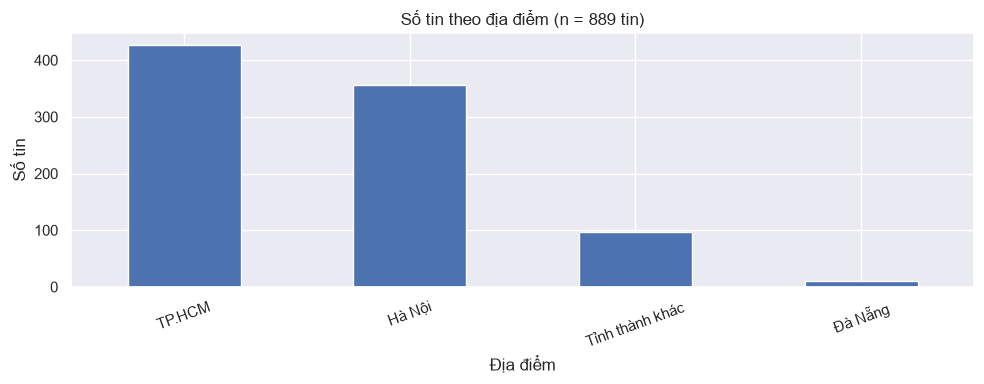

,Job_Count,Percent (%)
sql,449,50.51
python,342,38.47
excel,253,28.46
machine_learning,163,18.34
power_bi,152,17.10
docker,111,12.49
oracle,108,12.15
git,103,11.59
postgresql,95,10.69
java,92,10.35


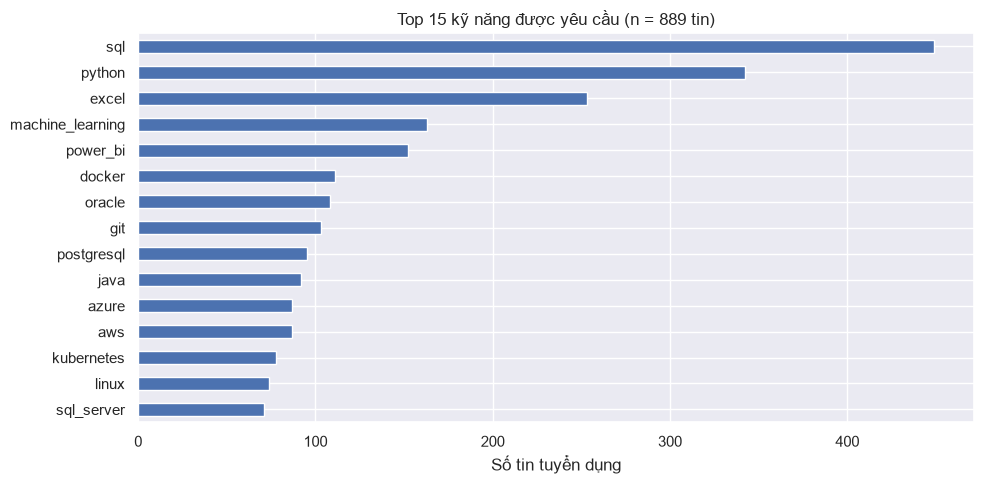

Kinh nghiệm (năm) — n_valid = 797, missing = 92


count    797.00
mean       2.66
std        1.80
min        0.00
25%        1.00
50%        3.00
75%        3.08
max       15.00
Name: Experience_Years, dtype: float64

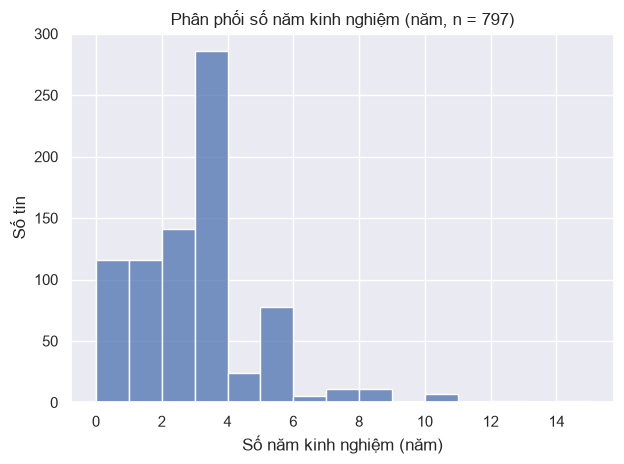

In [10]:
# 5. EDA — Đọc từ clean_data.csv: Địa điểm, Top 15 kỹ năng, Kinh nghiệm
df = pd.read_csv(CLEAN_PATH)
skill_cols = [c for c in df.columns if c.startswith("Skill_")]
print(f"Tổng số mẫu phân tích: n = {len(df)} tin tuyển dụng")

if "Location_Normalized" in df.columns:
    loc_tbl = df["Location_Normalized"].value_counts().to_frame("Job_Count")
    loc_tbl["Percent (%)"] = (loc_tbl["Job_Count"] / len(df) * 100).round(2)
    display(loc_tbl)
    ax = loc_tbl["Job_Count"].plot(kind="bar", figsize=(10, 4), title=f"Số tin theo địa điểm (n = {len(df)} tin)")
    plt.xlabel("Địa điểm"); plt.ylabel("Số tin"); plt.xticks(rotation=20); plt.tight_layout(); plt.show()

if skill_cols:
    skill_counts = df[skill_cols].sum().sort_values(ascending=False).head(15)
    skill_tbl = skill_counts.to_frame("Job_Count")
    skill_tbl["Percent (%)"] = (skill_tbl["Job_Count"] / len(df) * 100).round(2)
    skill_tbl.index = skill_tbl.index.str.replace("Skill_", "", regex=False)
    display(skill_tbl)
    skill_tbl["Job_Count"].sort_values().plot(kind="barh", figsize=(10, 5), title=f"Top 15 kỹ năng được yêu cầu (n = {len(df)} tin)")
    plt.xlabel("Số tin tuyển dụng"); plt.tight_layout(); plt.show()

if "Experience_Years" in df.columns:
    exp_valid = df["Experience_Years"].dropna()
    print(f"Kinh nghiệm (năm) — n_valid = {len(exp_valid)}, missing = {df['Experience_Years'].isna().sum()}")
    display(exp_valid.describe().round(2))
    sns.histplot(exp_valid, bins=15)
    plt.title(f"Phân phối số năm kinh nghiệm (năm, n = {len(exp_valid)})")
    plt.xlabel("Số năm kinh nghiệm (năm)"); plt.ylabel("Số tin"); plt.tight_layout(); plt.show()


Phân bố Seniority_EDA (toàn tập, n = 889 ):


,Job_Count
Seniority_EDA,
Fresher,217
Senior,194
Middle,182
Junior,127
Lead,108
NaN,61


Số tin có thông tin lương định lượng: n = 219 / 889 (Negotiable: 669)


Luong_Min                          Luong_Max              \
                    count      median         mean     count      median   
Salary_Currency                                                            
SGD                     1      3500.0      3500.00         1      5000.0   
USD                    58      1000.0      1081.38        60      1900.0   
VND                   153  18000000.0  18436601.31       158  25000000.0   

                              
                        mean  
Salary_Currency               
SGD                  5000.00  
USD                  1970.00  
VND              28285654.01


Lương (triệu VNĐ/tháng) theo Seniority (n_valid = 199):


,count,min,median,mean,max,Đủ mẫu (n>=5)
Seniority_EDA,,,,,,
Fresher,58,0.5,19.00,20.41,65.00,True
Junior,34,10.5,21.25,22.20,35.00,True
Middle,44,9.0,26.25,32.07,85.00,True
Senior,40,13.5,35.62,38.03,81.25,True
Lead,23,13.5,27.50,33.66,81.25,True


d:\IT SUBJECTS\KHAI PHA DU LIEU\DataMining_Tool\.venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


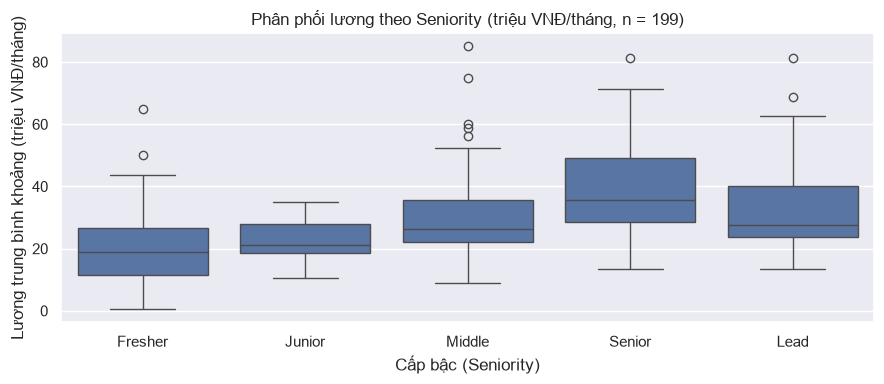


So sánh nhu cầu tuyển dụng & kinh nghiệm theo khu vực:


,Job_Count,Exp_Valid_n,Exp_Median_Years,Exp_Mean_Years
Location_Normalized,,,,
TP.HCM,426,388,3.0,2.58
Hà Nội,356,319,3.0,2.69
Đà Nẵng,10,9,2.0,2.00



So sánh mức lương (triệu VNĐ/tháng) theo khu vực:


,count,min,median,mean,max,Đủ mẫu (n>=5)
Location_Normalized,,,,,,
TP.HCM,99,0.50,27.50,29.19,81.25,True
Hà Nội,99,3.12,23.75,27.55,85.00,True
Đà Nẵng,2,21.50,45.12,45.12,68.75,False


LƯU Ý: Đà Nẵng chỉ có n = 2 mẫu lương (< 5), KHÔNG đủ cơ sở để kết luận mặt bằng lương.


d:\IT SUBJECTS\KHAI PHA DU LIEU\DataMining_Tool\.venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


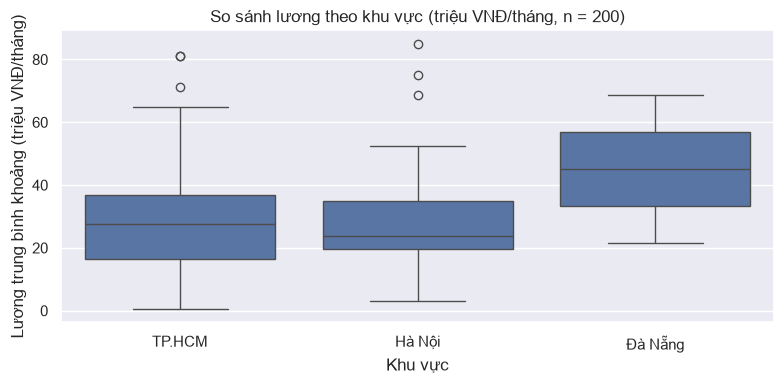

In [11]:
# 5.1. EDA Lương theo đơn vị, Seniority & So sánh Hà Nội / TP.HCM / Đà Nẵng
MIN_SAMPLE_NOTE = 5  # Ngưỡng tối thiểu để nhận xét thống kê

def infer_seniority(row):
    title = str(row.get("job_title", "")).lower()
    exp = row.get("Experience_Years", np.nan)
    if any(k in title for k in ["intern", "thực tập", "fresher"]): return "Fresher"
    if any(k in title for k in ["lead", "manager", "trưởng phòng", "head"]): return "Lead"
    if "senior" in title or "sr." in title: return "Senior"
    if "middle" in title or "mid-level" in title: return "Middle"
    if "junior" in title or "jr." in title: return "Junior"
    if pd.notna(exp):
        if exp <= 1: return "Fresher"
        if exp <= 2: return "Junior"
        if exp <= 4: return "Middle"
        return "Senior"
    return np.nan

df["Seniority_EDA"] = df.apply(infer_seniority, axis=1)
print("Phân bố Seniority_EDA (toàn tập, n =", len(df), "):")
display(df["Seniority_EDA"].value_counts(dropna=False).to_frame("Job_Count"))

# 1) Tách riêng theo từng loại tiền tệ gốc (VNĐ / USD / SGD)
if {"Luong_Min", "Luong_Max", "Salary_Currency"}.issubset(df.columns):
    sal_cur = df.dropna(subset=["Luong_Min", "Luong_Max"], how="all").copy()
    print(f"Số tin có thông tin lương định lượng: n = {len(sal_cur)} / {len(df)} (Negotiable: {(df['Salary_Type']=='Negotiable').sum()})")
    display(sal_cur.groupby("Salary_Currency")[["Luong_Min", "Luong_Max"]].agg(["count", "median", "mean"]).round(2))

# 2) Lương quy đổi VNĐ/tháng (triệu VNĐ/tháng) theo Seniority
if "Luong_Mid_VND" in df.columns:
    sal_vnd = df.dropna(subset=["Luong_Mid_VND"]).copy()
    sal_vnd["Luong_Mid_Trieu"] = sal_vnd["Luong_Mid_VND"] / 1e6
    order = ["Fresher", "Junior", "Middle", "Senior", "Lead"]
    sen_stats = sal_vnd.groupby("Seniority_EDA")["Luong_Mid_Trieu"].agg(["count", "min", "median", "mean", "max"]).reindex(order).round(2)
    sen_stats["Đủ mẫu (n>=5)"] = sen_stats["count"].fillna(0) >= MIN_SAMPLE_NOTE
    print(f"\nLương (triệu VNĐ/tháng) theo Seniority (n_valid = {sal_vnd['Seniority_EDA'].notna().sum()}):")
    display(sen_stats)

    plt.figure(figsize=(9, 4))
    plot_sen = sal_vnd[sal_vnd["Seniority_EDA"].isin(order)]
    sns.boxplot(data=plot_sen, x="Seniority_EDA", y="Luong_Mid_Trieu", order=order)
    plt.title(f"Phân phối lương theo Seniority (triệu VNĐ/tháng, n = {len(plot_sen)})")
    plt.xlabel("Cấp bậc (Seniority)"); plt.ylabel("Lương trung bình khoảng (triệu VNĐ/tháng)")
    plt.tight_layout(); plt.show()

# 3) So sánh Hà Nội vs TP.HCM vs Đà Nẵng
cities = ["TP.HCM", "Hà Nội", "Đà Nẵng"]
city_df = df[df["Location_Normalized"].isin(cities)].copy()
city_demand = city_df.groupby("Location_Normalized").agg(
    Job_Count=("url", "count"),
    Exp_Valid_n=("Experience_Years", "count"),
    Exp_Median_Years=("Experience_Years", "median"),
    Exp_Mean_Years=("Experience_Years", "mean"),
).reindex(cities).round(2)
print("\nSo sánh nhu cầu tuyển dụng & kinh nghiệm theo khu vực:")
display(city_demand)

if "Luong_Mid_VND" in df.columns:
    sal_city = sal_vnd[sal_vnd["Location_Normalized"].isin(cities)].copy()
    city_sal = sal_city.groupby("Location_Normalized")["Luong_Mid_Trieu"].agg(["count", "min", "median", "mean", "max"]).reindex(cities).round(2)
    city_sal["Đủ mẫu (n>=5)"] = city_sal["count"].fillna(0) >= MIN_SAMPLE_NOTE
    print("\nSo sánh mức lương (triệu VNĐ/tháng) theo khu vực:")
    display(city_sal)
    for c_name, row_c in city_sal.iterrows():
        if pd.isna(row_c["count"]) or row_c["count"] < MIN_SAMPLE_NOTE:
            print(f"LƯU Ý: {c_name} chỉ có n = {int(row_c['count'] or 0)} mẫu lương (< {MIN_SAMPLE_NOTE}), KHÔNG đủ cơ sở để kết luận mặt bằng lương.")

    plt.figure(figsize=(8, 4))
    sns.boxplot(data=sal_city, x="Location_Normalized", y="Luong_Mid_Trieu", order=cities)
    plt.title(f"So sánh lương theo khu vực (triệu VNĐ/tháng, n = {len(sal_city)})")
    plt.xlabel("Khu vực"); plt.ylabel("Lương trung bình khoảng (triệu VNĐ/tháng)")
    plt.tight_layout(); plt.show()

,Job_Count
Role_Group,
Khác (Dev/IT khác),641
Data/Business Analyst,138
Data Scientist/AI,79
Data Engineer,31


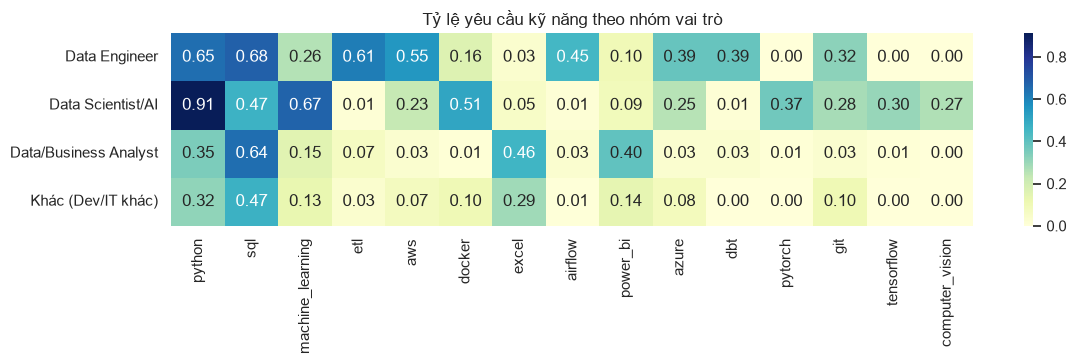

Lương (triệu VNĐ/tháng) theo vai trò — chỉ tin có lương số:


,count,median,mean,Đủ mẫu (n>=5)
Role_Group,,,,
Data Engineer,8,34.4,38.3,True
Data Scientist/AI,25,35.0,35.8,True
Data/Business Analyst,30,20.2,22.1,True
Khác (Dev/IT khác),156,23.8,27.4,True


In [12]:
# 5.2. Phân tích theo nhóm vai trò (suy từ tiêu đề): kỹ năng đặc trưng & lương
def role_of(t):
    t = str(t).lower()
    if re.search(r"data engineer|analytics engineer|etl|big data|data platform", t): return "Data Engineer"
    if re.search(r"data scien|machine learning|\bai\b|\bml\b|deep learning|nlp|computer vision", t): return "Data Scientist/AI"
    if re.search(r"data analy|business analy|\bbi\b|business intelligence|phân tích|reporting|analyst", t): return "Data/Business Analyst"
    return "Khác (Dev/IT khác)"
df["Role_Group"] = df["job_title"].apply(role_of)
display(df["Role_Group"].value_counts().to_frame("Job_Count"))
role_skill = df.groupby("Role_Group")[skill_cols].mean()
role_skill.columns = [c.replace("Skill_","") for c in role_skill.columns]
top_sk_global = role_skill.max().sort_values(ascending=False).head(15).index
plt.figure(figsize=(12,3.8)); sns.heatmap(role_skill[top_sk_global], annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Tỷ lệ yêu cầu kỹ năng theo nhóm vai trò"); plt.ylabel(""); plt.tight_layout(); plt.show()
if "Luong_Mid_VND" in df.columns:
    rs = df.dropna(subset=["Luong_Mid_VND"]).assign(M=lambda d: d["Luong_Mid_VND"]/1e6).groupby("Role_Group")["M"].agg(["count","median","mean"]).round(1)
    rs["Đủ mẫu (n>=5)"] = rs["count"] >= 5
    print("Lương (triệu VNĐ/tháng) theo vai trò — chỉ tin có lương số:"); display(rs)

Feature matrix: 889 mẫu × 47 đặc trưng | Missing trước impute: 92


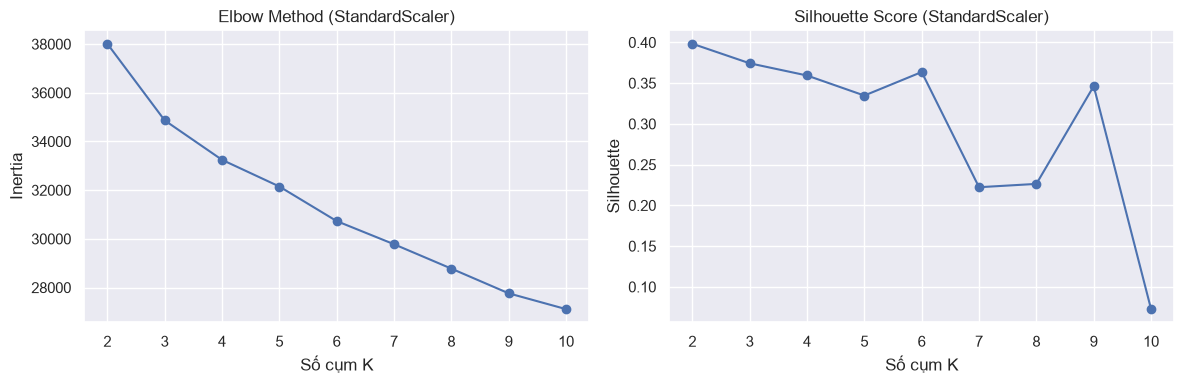

,K,Inertia,Silhouette
0,2,38014.12,0.3983
1,3,34866.31,0.3743
2,4,33245.29,0.3593
3,5,32149.43,0.3347
4,6,30729.10,0.3636
5,7,29778.30,0.2222
6,8,28776.29,0.2263
7,9,27761.43,0.3463
8,10,27112.63,0.0726


In [13]:
# 7. Clustering — K-Means (Kiểm tra ma trận đặc trưng, loại ID/leakage, chuẩn hóa StandardScaler, Elbow & Silhouette)
from sklearn.preprocessing import StandardScaler

if "df" not in globals() or not any(c.startswith("Skill_") for c in df.columns):
    df = pd.read_csv(CLEAN_PATH)
skill_cols = [c for c in df.columns if c.startswith("Skill_")]

# Chỉ chọn kỹ năng (nhị phân) + Experience_Years; loại bỏ hoàn toàn ID, URL, lương, target
leak_or_id = {"Job_ID", "url", "URL_Goc", "Luong_Min", "Luong_Max", "Luong_Min_VND", "Luong_Max_VND", "Luong_Mid_VND", "Seniority_EDA", "Seniority_Target", "Cluster"}
cluster_features = [c for c in skill_cols if c not in leak_or_id]
if "Experience_Years" in df.columns:
    cluster_features.append("Experience_Years")

assert not (set(cluster_features) & leak_or_id), "Phát hiện cột ID/leakage trong feature matrix!"
X_cluster_raw = df[cluster_features].replace([np.inf, -np.inf], np.nan)
X_cluster_raw = X_cluster_raw.loc[:, X_cluster_raw.nunique(dropna=True) > 1]
print(f"Feature matrix: {X_cluster_raw.shape[0]} mẫu × {X_cluster_raw.shape[1]} đặc trưng | Missing trước impute: {int(X_cluster_raw.isna().sum().sum())}")

# Impute median cho Experience_Years (không gán 0) rồi chuẩn hóa StandardScaler
X_cluster_imp = SimpleImputer(strategy="median").fit_transform(X_cluster_raw)
X_cluster_scaled = StandardScaler().fit_transform(X_cluster_imp)

ks = list(range(2, min(10, len(X_cluster_scaled) - 1) + 1))
inertias, sils = [], []
for k in ks:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = model.fit_predict(X_cluster_scaled)
    inertias.append(model.inertia_)
    sils.append(silhouette_score(X_cluster_scaled, labels))

k_metrics = pd.DataFrame({"K": ks, "Inertia": np.round(inertias, 2), "Silhouette": np.round(sils, 4)})
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertias, marker="o"); ax[0].set(title="Elbow Method (StandardScaler)", xlabel="Số cụm K", ylabel="Inertia")
ax[1].plot(ks, sils, marker="o"); ax[1].set(title="Silhouette Score (StandardScaler)", xlabel="Số cụm K", ylabel="Silhouette")
plt.tight_layout(); plt.show()
display(k_metrics)


Chọn K = 3 (Silhouette = 0.3743; lưu ý K=2 có Silhouette=0.3983 nhưng chỉ tách 1 nhóm nhỏ khỏi phần còn lại, quá thô để phân khúc).


,Job_Count,Percent (%)
Cluster,,
0,728,81.89
1,28,3.15
2,133,14.96


,Cluster,Job_Count,Percent (%),Exp_Valid_n,Exp_Mean_Years,Top_Skills
0,0,728,81.89,653,2.72,"sql (49%), excel (34%), python (33%), power_bi (20%), machine_learning (13%), oracle (8%)"
1,1,28,3.15,21,2.06,"python (100%), pytorch (93%), tensorflow (89%), machine_learning (89%), computer_vision (54%), docker (54%)"
2,2,133,14.96,123,2.40,"docker (61%), sql (59%), postgresql (59%), python (57%), kubernetes (49%), git (46%)"


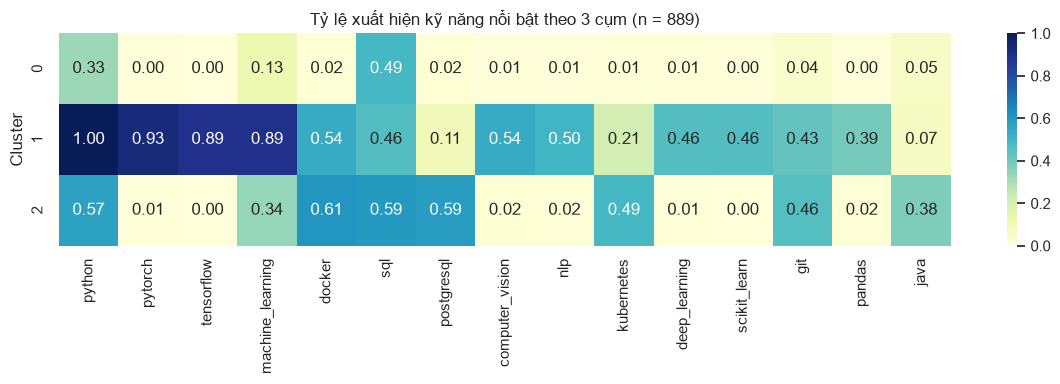

In [14]:
# 7.1. Chọn K có căn cứ (Elbow + đỉnh Silhouette ở K >= 3) & Diễn giải chân dung cụm
cand = k_metrics[k_metrics["K"] >= 3]
CHOSEN_K = int(cand.loc[cand["Silhouette"].idxmax(), "K"])
chosen_sil = float(cand.loc[cand["Silhouette"].idxmax(), "Silhouette"])
print(f"Chọn K = {CHOSEN_K} (Silhouette = {chosen_sil:.4f}; lưu ý K=2 có Silhouette={k_metrics.loc[k_metrics['K']==2, 'Silhouette'].values[0]:.4f} nhưng chỉ tách 1 nhóm nhỏ khỏi phần còn lại, quá thô để phân khúc).")

km = KMeans(n_clusters=CHOSEN_K, random_state=RANDOM_STATE, n_init=20)
df["Cluster"] = km.fit_predict(X_cluster_scaled)

size_tbl = df["Cluster"].value_counts().sort_index().to_frame("Job_Count")
size_tbl["Percent (%)"] = (size_tbl["Job_Count"] / len(df) * 100).round(2)
display(size_tbl)

sk_in_cluster = [c for c in X_cluster_raw.columns if c.startswith("Skill_")]
profile_skills = df.groupby("Cluster")[sk_in_cluster].mean()
exp_stats = df.groupby("Cluster")["Experience_Years"].agg(["count", "median", "mean"]).round(2)

# Diễn giải tự động từng cụm bằng top 6 kỹ năng đặc trưng & kinh nghiệm
rows_summary = []
for cid in sorted(df["Cluster"].unique()):
    top_sk = profile_skills.loc[cid].sort_values(ascending=False).head(6)
    top_str = ", ".join([f"{k.replace('Skill_', '')} ({v*100:.0f}%)" for k, v in top_sk.items() if v > 0])
    n_c = int(size_tbl.loc[cid, "Job_Count"])
    rows_summary.append({
        "Cluster": cid,
        "Job_Count": n_c,
        "Percent (%)": round(n_c / len(df) * 100, 2),
        "Exp_Valid_n": int(exp_stats.loc[cid, "count"]),
        "Exp_Mean_Years": exp_stats.loc[cid, "mean"],
        "Top_Skills": top_str,
    })
cluster_summary = pd.DataFrame(rows_summary)
display(cluster_summary)

# Heatmap tỷ lệ kỹ năng nổi bật theo cụm
top_var_skills = profile_skills.max(axis=0).sort_values(ascending=False).head(15).index.tolist()
plt.figure(figsize=(12, 4))
hm = profile_skills[top_var_skills].copy()
hm.columns = [c.replace("Skill_", "") for c in hm.columns]
sns.heatmap(hm, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title(f"Tỷ lệ xuất hiện kỹ năng nổi bật theo {CHOSEN_K} cụm (n = {len(df)})")
plt.ylabel("Cluster"); plt.tight_layout(); plt.show()


,Method,K,Silhouette,Davies-Bouldin (thấp tốt hơn)
0,K-Means,3,0.3743,2.2662
1,Hierarchical (Ward),3,0.3818,2.5305


Adjusted Rand Index K-Means vs Hierarchical: 0.5597


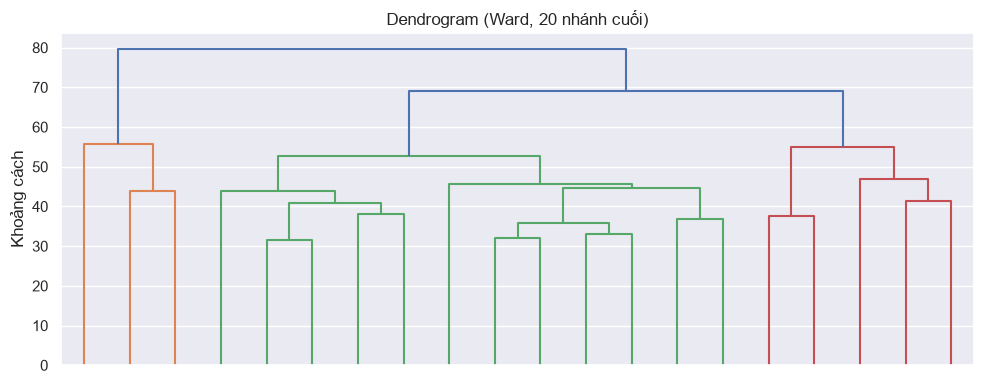

Cụm 0 (n=728): nổi bật so với toàn tập -> excel, power_bi, sas, vba
Cụm 1 (n=28): nổi bật so với toàn tập -> pytorch, tensorflow, machine_learning, python
Cụm 2 (n=133): nổi bật so với toàn tập -> postgresql, kubernetes, docker, java


In [15]:
# 7.2. Hierarchical Clustering (Ward) đối sánh K-Means + Davies-Bouldin + dendrogram
from scipy.cluster.hierarchy import linkage, dendrogram
agg = AgglomerativeClustering(n_clusters=CHOSEN_K, linkage="ward")
lab_h = agg.fit_predict(X_cluster_scaled)
cmp_cl = pd.DataFrame({
    "Method": ["K-Means", "Hierarchical (Ward)"],
    "K": [CHOSEN_K, CHOSEN_K],
    "Silhouette": [silhouette_score(X_cluster_scaled, df["Cluster"]), silhouette_score(X_cluster_scaled, lab_h)],
    "Davies-Bouldin (thấp tốt hơn)": [davies_bouldin_score(X_cluster_scaled, df["Cluster"]), davies_bouldin_score(X_cluster_scaled, lab_h)],
}).round(4)
display(cmp_cl)
print("Adjusted Rand Index K-Means vs Hierarchical:", round(adjusted_rand_score(df["Cluster"], lab_h), 4))
Z = linkage(X_cluster_scaled, method="ward")
plt.figure(figsize=(10,4)); dendrogram(Z, truncate_mode="lastp", p=20, no_labels=True)
plt.title("Dendrogram (Ward, 20 nhánh cuối)"); plt.ylabel("Khoảng cách"); plt.tight_layout(); plt.show()
# Đặt tên cụm gợi ý theo kỹ năng nổi bật nhất so với trung bình toàn tập
lift_prof = profile_skills / profile_skills.mean()
for cid in sorted(df["Cluster"].unique()):
    sig = (profile_skills.loc[cid] - profile_skills.mean()).sort_values(ascending=False).head(4)
    print(f"Cụm {cid} (n={int((df['Cluster']==cid).sum())}): nổi bật so với toàn tập -> " + ", ".join(k.replace('Skill_','') for k in sig.index))

In [16]:
# 8. Association Rules — FP-Growth (loại luật đối xứng, hiển thị dạng chuỗi)
if skill_cols:
    transactions = df[skill_cols].astype(bool)
    transactions.columns = [c.replace("Skill_","") for c in transactions.columns]
    display(transactions.mean().sort_values(ascending=False).head(30).to_frame("Support"))
    MIN_SUPPORT = 0.03
    frequent = fpgrowth(transactions, min_support=MIN_SUPPORT, use_colnames=True)
    print("Số frequent itemsets:", len(frequent))
    rules = association_rules(frequent, metric="confidence", min_threshold=0.30)
    selected_rules = rules[rules["lift"] > 1.2].copy()
    # Với mỗi tập mục (antecedent ∪ consequent) giữ luật có confidence cao nhất -> bỏ luật đối xứng
    selected_rules["_k"] = selected_rules.apply(lambda r: frozenset(r["antecedents"] | r["consequents"]), axis=1)
    selected_rules = (selected_rules.sort_values(["confidence","lift"], ascending=False)
                      .drop_duplicates("_k").drop(columns="_k"))
    selected_rules["Luat"] = selected_rules.apply(lambda r: " + ".join(sorted(r["antecedents"])) + "  =>  " + " + ".join(sorted(r["consequents"])), axis=1)
    selected_rules = selected_rules.sort_values(["lift","confidence"], ascending=False)
    print(f"Luật sau lọc (lift > 1.2, bỏ đối xứng): {len(selected_rules)}")
    display(selected_rules[["Luat","support","confidence","lift","conviction"]].head(25).round(3))
else:
    print("Chưa có cột kỹ năng one-hot.")

,Support
sql,0.505062
python,0.384702
excel,0.284589
machine_learning,0.183352
power_bi,0.170979
docker,0.124859
oracle,0.121485
git,0.115861
postgresql,0.106862
java,0.103487


Số frequent itemsets: 147
Luật sau lọc (lift > 1.2, bỏ đối xứng): 100


,Luat,support,confidence,lift,conviction
86,docker + mongodb => kubernetes,0.030,0.964,10.990,25.543
211,azure + gcp => aws,0.031,1.000,10.218,inf
206,gcp => aws,0.040,0.900,9.197,9.021
232,redis => postgresql,0.037,0.846,7.918,5.805
55,kubernetes + sql => docker,0.043,0.927,7.423,11.960
208,gcp => azure,0.031,0.700,7.153,3.007
32,git + postgresql => docker,0.035,0.886,7.094,7.657
144,azure => aws,0.066,0.678,6.930,2.803
79,mongodb => postgresql,0.039,0.729,6.823,3.298
60,kubernetes + postgresql => docker,0.038,0.850,6.808,5.834


In [17]:
# Classification — nhãn 3 lớp từ Seniority (tiêu đề + số năm kinh nghiệm) để tránh lớp quá hiếm
SEN_MAP = {"Fresher":"Junior-", "Junior":"Junior-", "Middle":"Middle", "Senior":"Senior+", "Lead":"Senior+"}
df["Seniority_Target"] = df["Seniority_EDA"].map(SEN_MAP)
display(df["Seniority_Target"].value_counts(dropna=False))
TARGET = "Seniority_Target"

Seniority_Target
Junior-    344
Senior+    302
Middle     182
NaN         61
Name: count, dtype: int64

In [18]:
# Chia train/test và tiền xử lý
model_df=df.dropna(subset=[TARGET]).copy()
y=model_df[TARGET].astype(str)
X_cols=skill_cols.copy()
if "Location_Normalized" in model_df.columns: X_cols.append("Location_Normalized")
X=model_df[X_cols].copy()

counts=y.value_counts()
keep=y.isin(counts[counts>=2].index)
X,y=X.loc[keep],y.loc[keep]
display(y.value_counts())

if y.nunique()>=2 and len(y)>=10:
    X_train,X_test,y_train,y_test=train_test_split(
        X,y,test_size=0.2,random_state=RANDOM_STATE,stratify=y)
    numeric=[c for c in X.columns if c.startswith("Skill_")]
    categorical=[c for c in X.columns if c=="Location_Normalized"]
    prep=ColumnTransformer([
        ("num",SimpleImputer(strategy="median"),numeric),
        ("cat",Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),
                         ("onehot",OneHotEncoder(handle_unknown="ignore"))]),categorical)
    ])
else:
    print("Không đủ dữ liệu/lớp để train-test stratified split.")

Seniority_Target
Junior-    344
Senior+    302
Middle     182
Name: count, dtype: int64

Best params: {'tree__ccp_alpha': np.float64(0.0026726708049539315)}


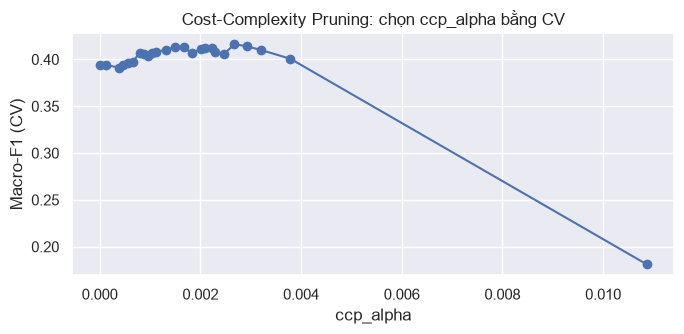

Số lá của cây tối ưu: 37


In [19]:
# Decision Tree — chọn ccp_alpha bằng cross-validation trên train
if "X_train" in globals():
    path_model=Pipeline([("prep",prep),("tree",DecisionTreeClassifier(random_state=RANDOM_STATE,class_weight="balanced"))])
    path_model.fit(X_train,y_train)
    Xtr=path_model.named_steps["prep"].transform(X_train)
    pruning=DecisionTreeClassifier(random_state=RANDOM_STATE).cost_complexity_pruning_path(Xtr,y_train)
    alphas=np.unique(pruning.ccp_alphas)
    if len(alphas)>25: alphas=np.unique(np.quantile(alphas,np.linspace(0,1,25)))
    min_class=int(y_train.value_counts().min())
    if min_class>=2:
        cv=StratifiedKFold(n_splits=min(5,min_class),shuffle=True,random_state=RANDOM_STATE)
        grid=GridSearchCV(path_model,{"tree__ccp_alpha":alphas},scoring="f1_macro",cv=cv,n_jobs=-1)
        grid.fit(X_train,y_train)
        dt_model=grid.best_estimator_
        print("Best params:",grid.best_params_)
    else: print("Một lớp có dưới 2 mẫu trong train; cần gộp/loại lớp hoặc thêm dữ liệu.")
    if 'grid' in globals():
        res = pd.DataFrame({"alpha": grid.cv_results_["param_tree__ccp_alpha"].astype(float), "f1_macro_cv": grid.cv_results_["mean_test_score"]})
        plt.figure(figsize=(7,3.5)); plt.plot(res["alpha"], res["f1_macro_cv"], marker="o")
        plt.xlabel("ccp_alpha"); plt.ylabel("Macro-F1 (CV)"); plt.title("Cost-Complexity Pruning: chọn ccp_alpha bằng CV"); plt.tight_layout(); plt.show()
        print("Số lá của cây tối ưu:", dt_model.named_steps["tree"].get_n_leaves())

In [20]:
# Mô hình đối sánh — Random Forest
if "X_train" in globals():
    rf_model=Pipeline([("prep",prep),("rf",RandomForestClassifier(
        n_estimators=300,random_state=RANDOM_STATE,class_weight="balanced",min_samples_leaf=2))])
    rf_model.fit(X_train,y_train)

In [21]:
# Mô hình đối sánh — Logistic Regression & KNN
if "X_train" in globals():
    lr_model = Pipeline([("prep", prep), ("lr", LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE))]).fit(X_train, y_train)
    knn_model = Pipeline([("prep", prep), ("knn", KNeighborsClassifier(n_neighbors=7))]).fit(X_train, y_train)

Decision Tree (pruned)
              precision    recall  f1-score   support

     Junior-       0.45      0.26      0.33        69
      Middle       0.24      0.42      0.31        36
     Senior+       0.41      0.43      0.42        61

    accuracy                           0.36       166
   macro avg       0.37      0.37      0.35       166
weighted avg       0.39      0.36      0.36       166



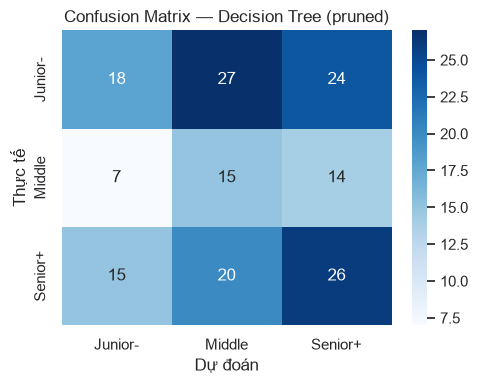

Random Forest
              precision    recall  f1-score   support

     Junior-       0.52      0.48      0.50        69
      Middle       0.20      0.28      0.24        36
     Senior+       0.43      0.38      0.40        61

    accuracy                           0.40       166
   macro avg       0.38      0.38      0.38       166
weighted avg       0.42      0.40      0.41       166



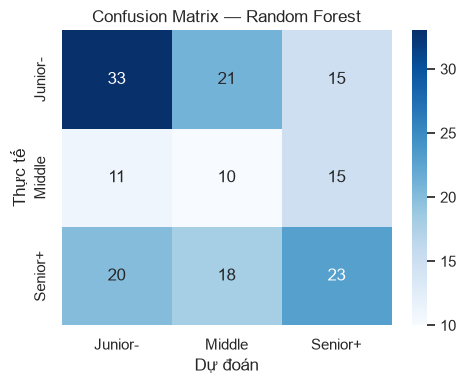

Logistic Regression
              precision    recall  f1-score   support

     Junior-       0.47      0.39      0.43        69
      Middle       0.19      0.28      0.23        36
     Senior+       0.45      0.41      0.43        61

    accuracy                           0.37       166
   macro avg       0.37      0.36      0.36       166
weighted avg       0.40      0.37      0.38       166



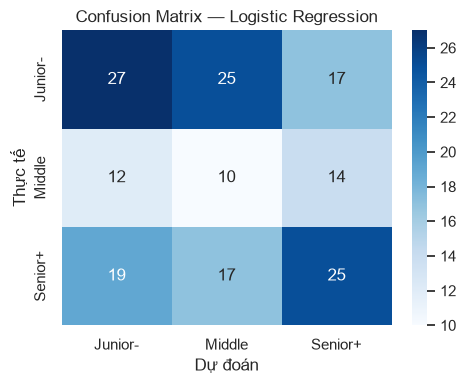

KNN (k=7)
              precision    recall  f1-score   support

     Junior-       0.43      0.54      0.47        69
      Middle       0.22      0.11      0.15        36
     Senior+       0.43      0.43      0.43        61

    accuracy                           0.40       166
   macro avg       0.36      0.36      0.35       166
weighted avg       0.38      0.40      0.39       166



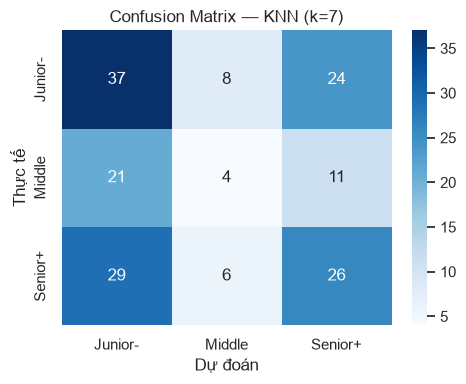

,Model,Accuracy,Precision_macro,Recall_macro,F1_macro,CV5_F1_macro_mean,CV5_F1_macro_std
1,Random Forest,0.3976,0.3846,0.3777,0.3783,0.4080,0.0271
2,Logistic Regression,0.3735,0.3681,0.3596,0.3599,0.3859,0.0387
0,Decision Tree (pruned),0.3554,0.3661,0.3679,0.3508,0.3855,0.0402
3,KNN (k=7),0.4036,0.3579,0.3579,0.3496,0.3791,0.0350


In [22]:
# Confusion Matrix, Precision, Recall, Macro F1 — so sánh các mô hình
def evaluate(model, name):
    pred = model.predict(X_test)
    print(name); print(classification_report(y_test, pred, zero_division=0))
    p, r, f, _ = precision_recall_fscore_support(y_test, pred, average="macro", zero_division=0)
    labels = sorted(set(y_test) | set(pred))
    cm = confusion_matrix(y_test, pred, labels=labels)
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt="d", xticklabels=labels, yticklabels=labels, cmap="Blues")
    plt.xlabel("Dự đoán"); plt.ylabel("Thực tế"); plt.title("Confusion Matrix — " + name); plt.tight_layout(); plt.show()
    return {"Model": name, "Accuracy": accuracy_score(y_test, pred), "Precision_macro": p, "Recall_macro": r, "F1_macro": f}

if "X_test" in globals():
    all_models = {"Decision Tree (pruned)": dt_model, "Random Forest": rf_model, "Logistic Regression": lr_model, "KNN (k=7)": knn_model}
    rows = [evaluate(m, n) for n, m in all_models.items()]
    cv_all = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    base_models = {"Decision Tree (pruned)": dt_model, "Random Forest": rf_model, "Logistic Regression": lr_model, "KNN (k=7)": knn_model}
    for r_ in rows:
        sc = cross_val_score(base_models[r_["Model"]], X, y, cv=cv_all, scoring="f1_macro", n_jobs=-1)
        r_["CV5_F1_macro_mean"], r_["CV5_F1_macro_std"] = sc.mean(), sc.std()
    model_comparison = pd.DataFrame(rows).round(4).sort_values("F1_macro", ascending=False)
    display(model_comparison)

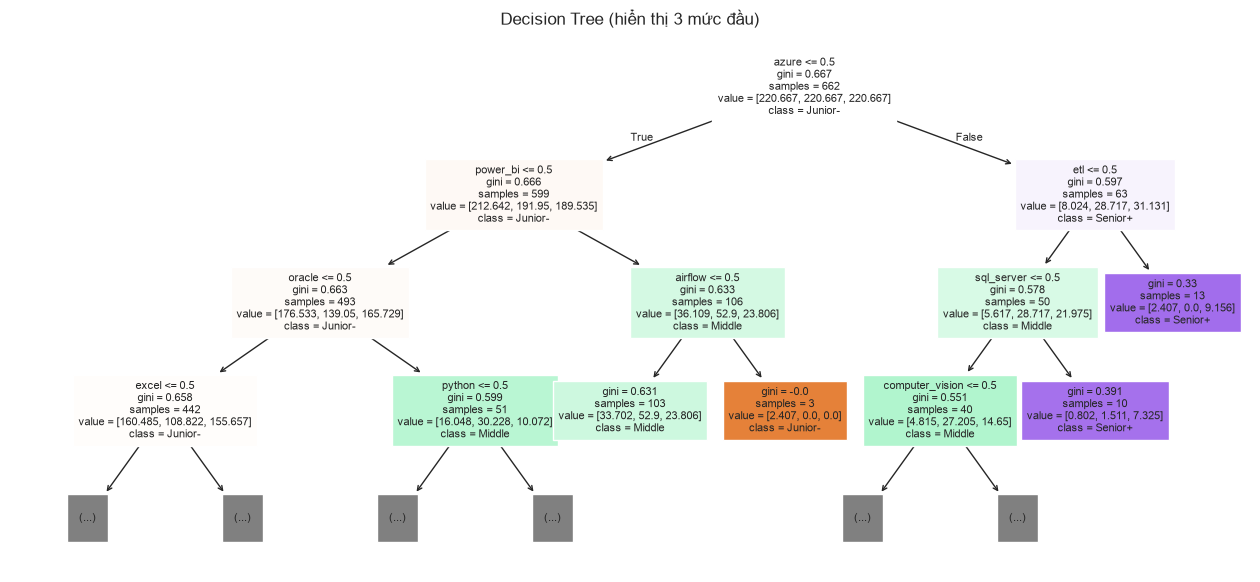

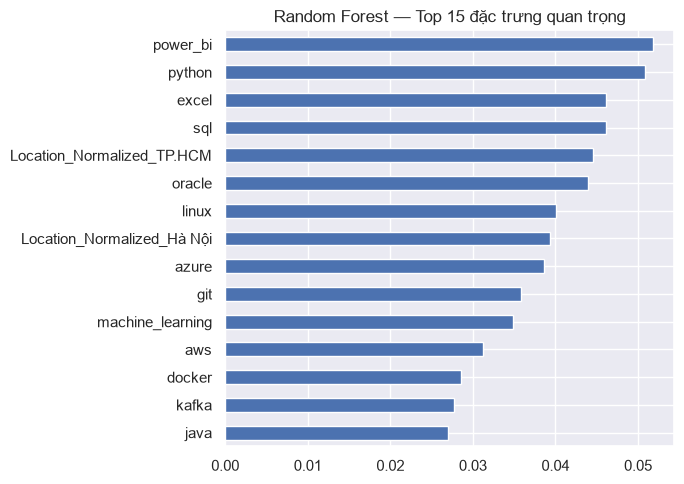

In [23]:
# Diễn giải mô hình: cấu trúc cây quyết định & độ quan trọng đặc trưng
if "dt_model" in globals():
    feat_names = [n.split("__",1)[-1].replace("Skill_","") for n in dt_model.named_steps["prep"].get_feature_names_out()]
    tree = dt_model.named_steps["tree"]
    plt.figure(figsize=(16,7))
    plot_tree(tree, feature_names=feat_names, class_names=list(tree.classes_), max_depth=3, filled=True, fontsize=8)
    plt.title("Decision Tree (hiển thị 3 mức đầu)"); plt.show()
    imp = pd.Series(rf_model.named_steps["rf"].feature_importances_, index=[n.split("__",1)[-1].replace("Skill_","") for n in rf_model.named_steps["prep"].get_feature_names_out()]).sort_values(ascending=False).head(15)
    imp.sort_values().plot(kind="barh", figsize=(7,5), title="Random Forest — Top 15 đặc trưng quan trọng"); plt.tight_layout(); plt.show()

In [24]:
# 10. Xuất kết quả cho báo cáo
if "skill_counts" in globals(): skill_counts.to_csv(DATA/"top_skills.csv", header=["Job_Count"], encoding="utf-8-sig")
if "selected_rules" in globals() and not selected_rules.empty:
    selected_rules.drop(columns=["antecedents","consequents"]).to_csv(DATA/"association_rules.csv", index=False, encoding="utf-8-sig")
if "cluster_summary" in globals(): cluster_summary.to_csv(DATA/"cluster_summary.csv", index=False, encoding="utf-8-sig")
if "model_comparison" in globals(): model_comparison.to_csv(DATA/"model_comparison.csv", index=False, encoding="utf-8-sig")
if "role_skill" in globals(): role_skill.to_csv(DATA/"skill_by_role.csv", encoding="utf-8-sig")
print("Đã xuất CSV vào", DATA.resolve(), "và hình vào", FIG_DIR.resolve())

Đã xuất CSV vào D:\IT SUBJECTS\KHAI PHA DU LIEU\DataMining_Tool\data và hình vào D:\IT SUBJECTS\KHAI PHA DU LIEU\DataMining_Tool\reports\figures
